# Radiographies thoraciques : 14 pathologies, évaluées comme un test diagnostique

Transfert d'apprentissage (DenseNet121, ImageNet) sur des radiographies NIH ChestX-ray8, classifieurs pondérés par
pathologie, calibration de Platt, puis évaluation : AUC avec IC bootstrap, sensibilité, spécificité, VPP, VPN, Grad-CAM.

Pour relancer : renseigner `CXR_IMAGES` et `CXR_LABELS` (voir README), puis exécuter les cellules.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data import PATHOLOGIES, NOMS_FR, config, load_labels, patient_split, check_no_overlap, image_paths, positives
from src.features import embeddings
from src.model import MultiLabelClassifier
from src.evaluation import report, brier

pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Données et découpage par patient

In [2]:
label_files, image_dir = config()
df = load_labels(label_files, image_dir)
tr, va, te = patient_split(df)
print(f"{len(df)} radiographies, {df['PatientId'].nunique()} patients")
print(f"train {len(tr)} | validation {len(va)} | test {len(te)} | aucun patient commun : {check_no_overlap(tr, va, te)}")
pd.DataFrame({"cas positifs (total)": positives(df), "prévalence": df[PATHOLOGIES].mean()}).rename(index=NOMS_FR).sort_values("prévalence")

1420 radiographies, 1317 patients
train 934 | validation 209 | test 277 | aucun patient commun : True


,cas positifs (total),prévalence
Hernie,52,0.037
Pneumonie,60,0.042
Œdème,66,0.046
Emphysème,69,0.049
Cardiomégalie,70,0.049
Fibrose,75,0.053
Épaississement pleural,79,0.056
Condensation,86,0.061
Pneumothorax,93,0.065
Masse,105,0.074


## 2. Caractéristiques DenseNet121 (réseau gelé, poids ImageNet)

In [3]:
E = embeddings(image_paths(df, image_dir))
idx = {f: i for i, f in enumerate(df["Image"])}
X = lambda d: E[[idx[f] for f in d["Image"]]]
Y = lambda d: d[PATHOLOGIES].to_numpy()
print("Matrice de caractéristiques :", E.shape)

Matrice de caractéristiques : (1420, 1024)


## 3. Un classifieur pondéré par pathologie, puis calibration de Platt

In [4]:
clf = MultiLabelClassifier().fit(X(tr), Y(tr), X(va), Y(va))
P_va, P_te, P_raw = clf.proba(X(va)), clf.proba(X(te)), clf.proba_brute(X(te))
print(f"Erreur de Brier sur le test : {brier(Y(te), P_raw):.3f} avant calibration → {brier(Y(te), P_te):.3f} après")

Erreur de Brier sur le test : 0.155 avant calibration → 0.072 après


## 4. Évaluation sur le jeu de test

Seuil choisi sur la validation (indice de Youden), puis appliqué au test.

In [5]:
r = report(Y(te), P_te, Y(va), P_va)
print(f"AUC moyenne : {r['AUC'].mean():.3f}")
r[["pathologie", "cas_positifs_test", "AUC", "IC95_bas", "IC95_haut", "sensibilite", "specificite", "VPP", "VPN"]]

AUC moyenne : 0.707


,pathologie,cas_positifs_test,AUC,IC95_bas,IC95_haut,sensibilite,specificite,VPP,VPN
0,Œdème,6,0.849,0.748,0.934,1.000,0.690,0.067,1.000
1,Hernie,17,0.823,0.745,0.893,0.824,0.650,0.133,0.983
2,Épanchement pleural,42,0.796,0.735,0.853,0.619,0.787,0.342,0.920
3,Emphysème,14,0.776,0.641,0.895,0.714,0.715,0.118,0.979
4,Épaississement pleural,12,0.746,0.631,0.854,0.917,0.483,0.074,0.992
5,Condensation,20,0.738,0.567,0.862,0.850,0.498,0.116,0.977
6,Atélectasie,37,0.730,0.633,0.810,0.811,0.550,0.217,0.950
7,Infiltration,49,0.692,0.606,0.771,0.673,0.636,0.284,0.901
8,Pneumonie,8,0.675,0.430,0.902,0.750,0.398,0.036,0.982
9,Pneumothorax,26,0.669,0.561,0.758,0.577,0.685,0.160,0.940


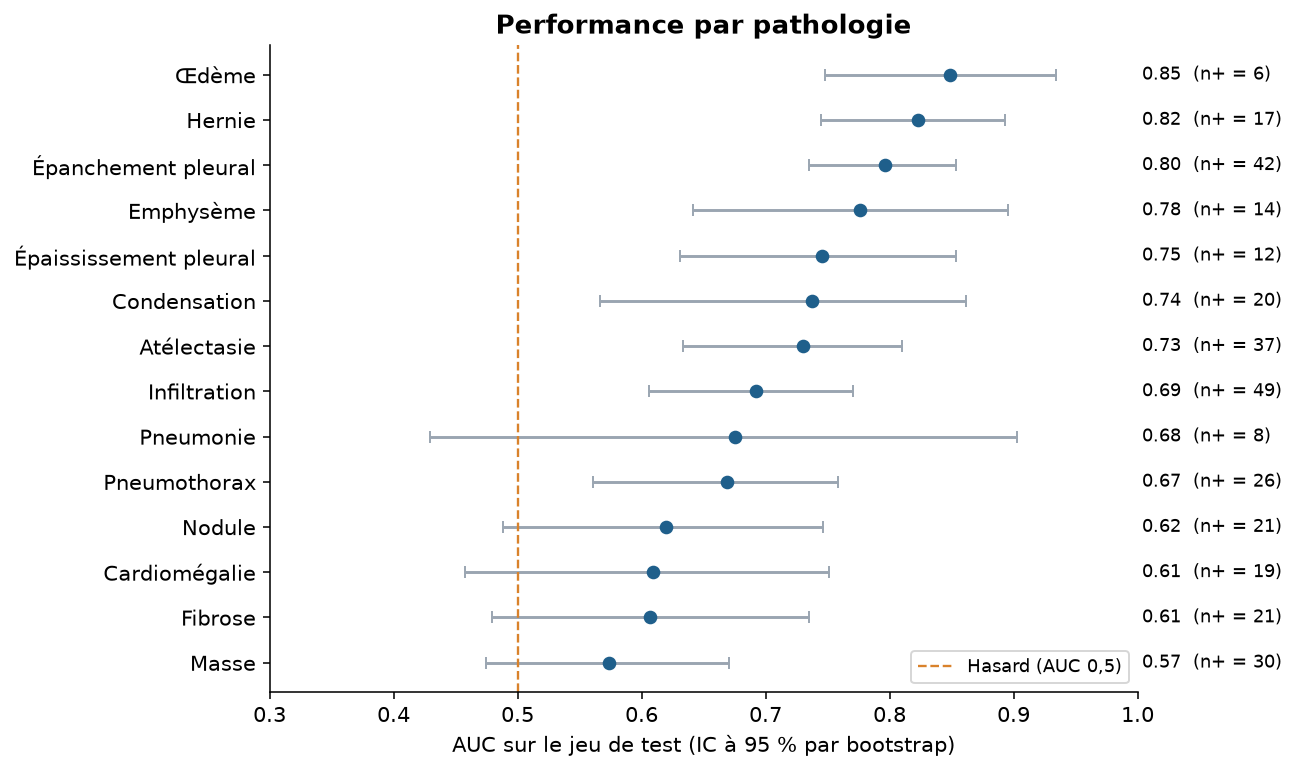

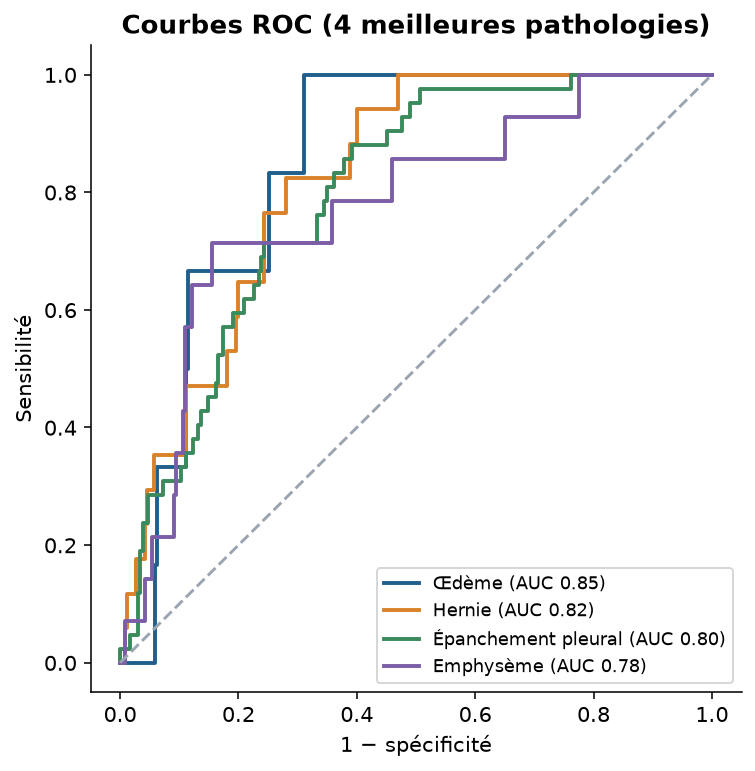

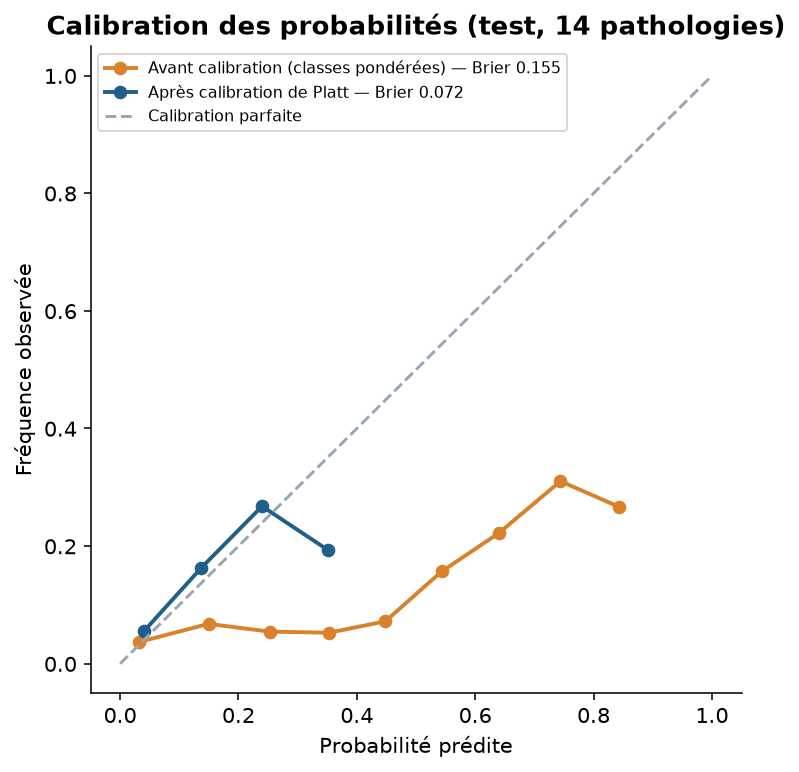

In [6]:
for f in ["auc_par_pathologie.png", "courbes_roc.png", "calibration.png"]:
    display(Image(f"../outputs/figures/{f}"))

## 5. Grad-CAM

Où le modèle regarde-t-il ? Souvent hors des poumons : une limite d'un réseau gelé entraîné sur des photos ordinaires.

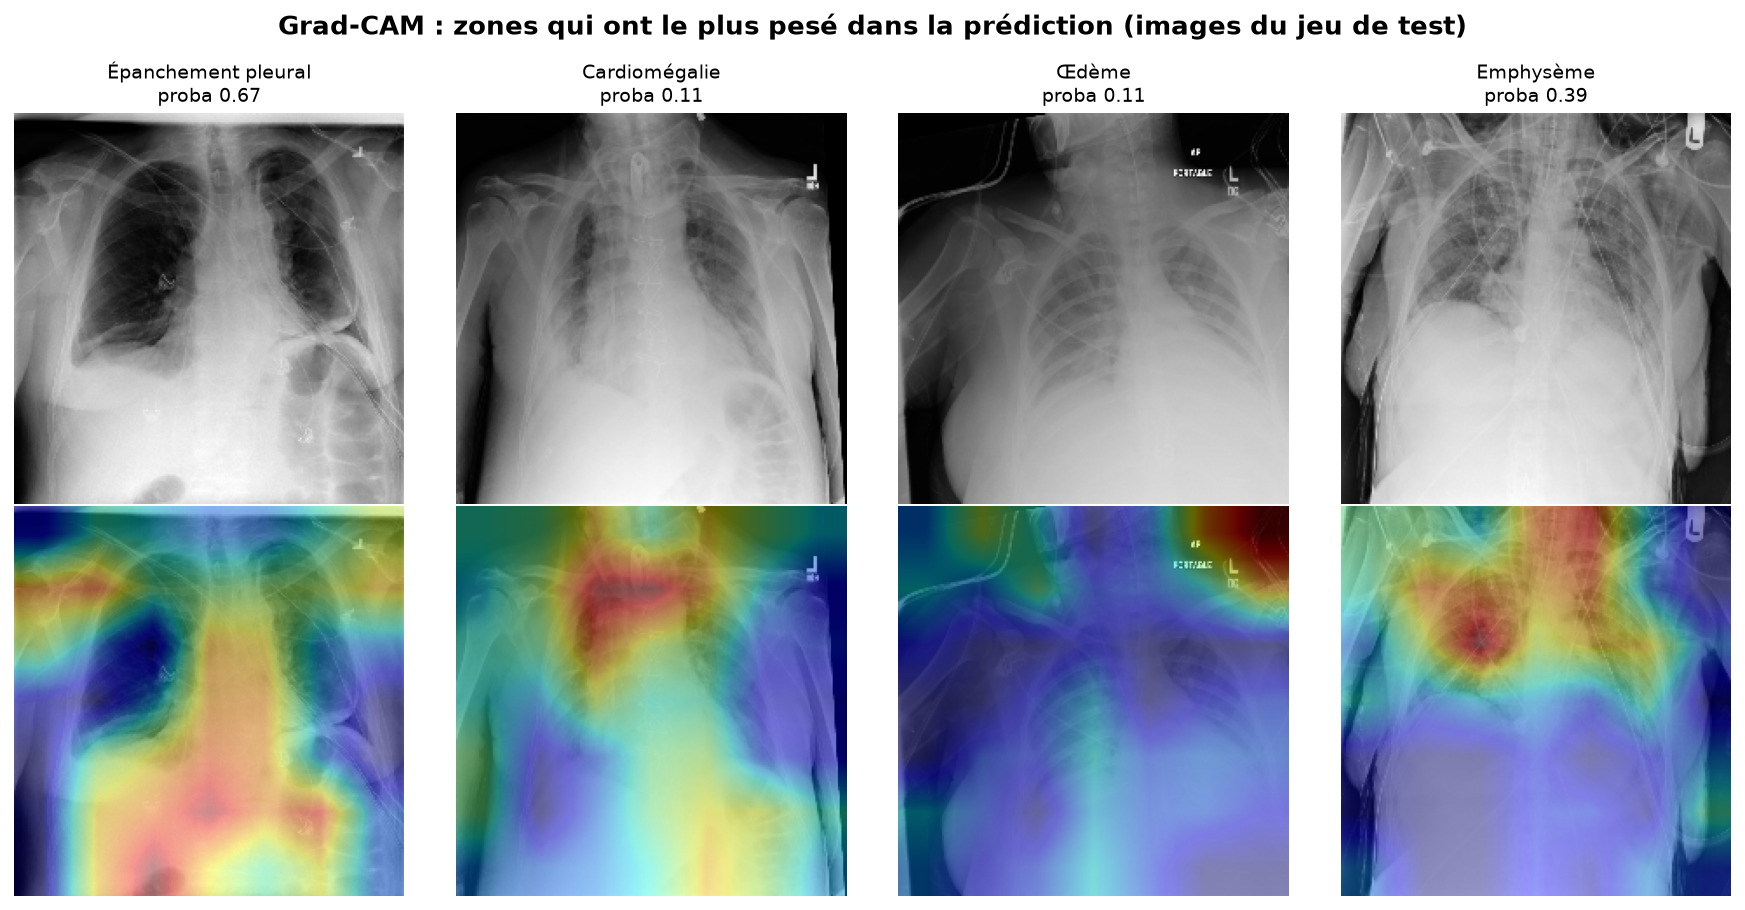

In [7]:
display(Image("../outputs/figures/gradcam.png"))

## Conclusion

- AUC moyenne d'environ 0,71 avec un réseau gelé et moins de 1 000 images d'entraînement.
- Bonne VPN, faible VPP : utile pour exclure ou trier, pas pour diagnostiquer seul.
- La calibration divise par deux l'erreur des probabilités.
- Grad-CAM montre des raccourcis d'apprentissage : un fine-tuning sur beaucoup plus de radiographies serait la prochaine étape.